# Notebook 1 · Modelo A: CNN desde cero (SMILES)
Clasificador binario **sonríe / no sonríe** sobre caras recortadas de 64x64 en escala de grises.

**Contrato de preprocesado (la app local debe respetarlo):** recorte de la cara → gris → 64x64 → `float32` con valores **0-255** → forma `(1, 64, 64, 1)`. El reescalado a 0-1 ya va dentro del modelo.

**Para ahorrar GPU:** primero corre con `QUICK_TEST = True` (2 épocas, sirve para depurar). Cuando todo funcione, pon `False` y haz *Save & Run All*.

In [1]:
# ==============================================================================
# 1. Configuración del entorno, importación de librerías y constantes globales
# ==============================================================================
# Se importan TensorFlow, Keras, scikit-learn (para partición estratificada y métricas)
# y utilidades para procesamiento numérico y visualización gráfica.
import os, glob, json, time, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score)

# Variable de control para pruebas rápidas de depuración (2 épocas vs 40 épocas completas)
QUICK_TEST = False          # <- False para el entrenamiento real completo

# Semilla aleatoria fija para asegurar la reproducibilidad de particiones y pesos
SEED = 42
# Dimensión de entrada requerida: 64x64 píxeles (contrato con la aplicación en tiempo real)
IMG_SIZE = 64
BATCH = 64
EPOCHS = 2 if QUICK_TEST else 40

# Rutas al dataset SMILEs estructurado en Kaggle
BASE    = "/kaggle/input/datasets/marcos03/smiles/SMILEs"
POS_DIR = f"{BASE}/positives/positives7"
NEG_DIR = f"{BASE}/negatives/negatives7"
OUT     = "/kaggle/working"

# Fijar semillas para reproducibilidad determinista
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Carga del dataset (smile = 1, no smile = 0)

In [2]:
# ==============================================================================
# 2. Carga y preprocesamiento del conjunto de datos SMILEs
# ==============================================================================
# Las imágenes se convierten a escala de grises ('L'), se redimensionan a 64x64
# y se almacenan como float32 con valores en rango [0, 255] y forma (N, 64, 64, 1).
# NOTA: La normalización [0, 1] se realiza dentro del propio modelo (capa Rescaling),
# garantizando coherencia idéntica durante el entrenamiento y la inferencia en vivo.
def list_images(folder):
    # Solo archivos directos de la carpeta (ignora subcarpetas duplicadas)
    return sorted(glob.glob(os.path.join(folder, "*.jpg")))

pos_paths = list_images(POS_DIR)
neg_paths = list_images(NEG_DIR)
print("positivas:", len(pos_paths), "| negativas:", len(neg_paths))
assert len(pos_paths) > 0 and len(neg_paths) > 0, "Revisa las rutas"

def load_images(paths):
    arr = [np.array(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE))) for p in paths]
    return np.stack(arr).astype("float32")[..., None]       # (N, 64, 64, 1), valores 0-255

X = np.concatenate([load_images(neg_paths), load_images(pos_paths)])
y = np.concatenate([np.zeros(len(neg_paths)), np.ones(len(pos_paths))]).astype("float32")
print("X:", X.shape, "| y:", y.shape, "| % sonrisas:", round(100 * y.mean(), 1))


positivas: 3690 | negativas: 9475
X: (13165, 64, 64, 1) | y: (13165,) | % sonrisas: 28.0


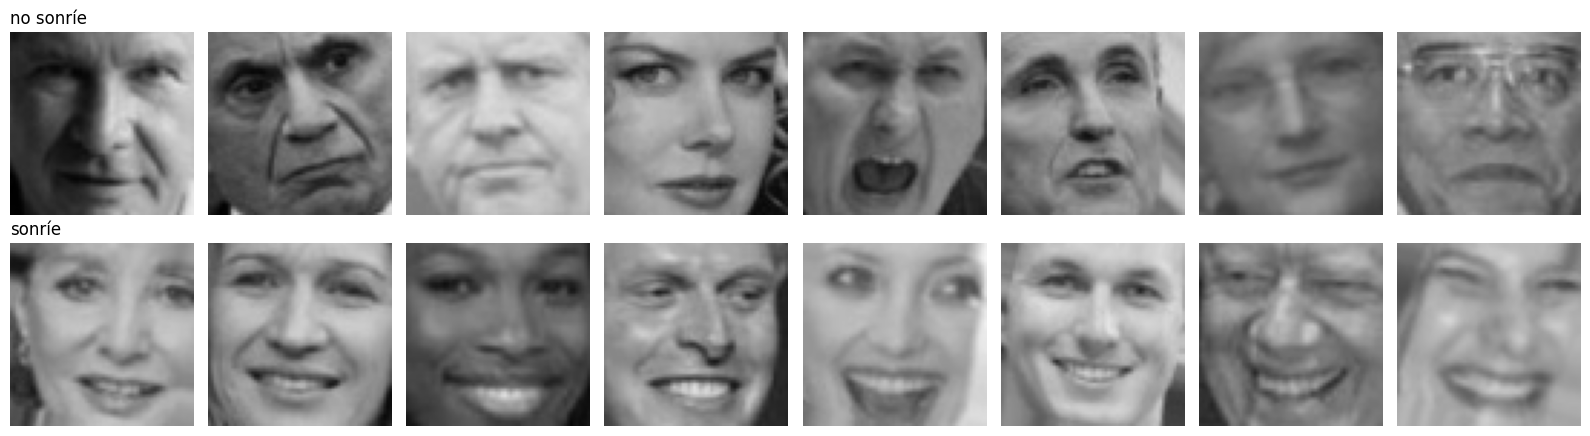

In [3]:
# ==============================================================================
# 3. Inspección visual de muestras del dataset (positivas y negativas)
# ==============================================================================
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
rng = np.random.default_rng(0)
for row, (cls, name) in enumerate([(0, "no sonríe"), (1, "sonríe")]):
    idx = rng.choice(np.where(y == cls)[0], 8, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(X[i, ..., 0], cmap="gray", vmin=0, vmax=255); ax.axis("off")
    axes[row][0].set_title(name, loc="left")
plt.tight_layout(); plt.show()


## 2. Split train / val / test (70 / 15 / 15, estratificado)
Con `SEED` fijo y la lista de archivos ordenada, el split es **idéntico en todos los notebooks**, así el Modelo B se compara en igualdad de condiciones.

In [4]:
# ==============================================================================
# 4. Partición estratificada (Train / Val / Test) y cálculo de pesos de clase
# ==============================================================================
# División: 70% entrenamiento, 15% validación, 15% evaluación final (test).
# La estratificación preserva la proporción natural de clases en cada subconjunto.
idx = np.arange(len(y))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]
print("train:", len(y_train), "| val:", len(y_val), "| test:", len(y_test))

# --- PESOS DE CLASE (class_weight) ---
# El dataset SMILEs presenta desbalance (mayoría de caras sin sonrisa).
# compute_class_weight("balanced") asigna a cada clase un peso inversamente proporcional
# a su frecuencia: peso = n_muestras / (n_clases * n_muestras_clase).
# Esto penaliza con mayor severidad los errores en la clase minoritaria (sonrisas),
# evitando que el modelo converja hacia una solución trivial que prediga siempre clase 0.
cw = compute_class_weight("balanced", classes=np.array([0., 1.]), y=y_train)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("class_weight:", class_weight)

# Pipelines optimizados con tf.data (shuffle, batch y prefetch asíncrono)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(y_train), seed=SEED).batch(BATCH).prefetch(AUTOTUNE))
val_ds   = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH).prefetch(AUTOTUNE)
test_ds  = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH).prefetch(AUTOTUNE)


train: 9215 | val: 1975 | test: 1975
class_weight: {0: 0.6947376357056695, 1: 1.783778552071235}


## 3. Modelo
La augmentation va dentro del modelo y **solo se activa al entrenar**. Está pensada para acercar SMILES a una webcam: flip, rotación, zoom, brillo y contraste.

In [5]:
# ==============================================================================
# 5. Arquitectura de la CNN desde cero (Modelo A)
# ==============================================================================
# Diseño convolucional jerárquico adaptado a recortes de rostros en escala de grises (64x64):
#   a) Capas de Data Augmentation: rotación leve (±8%), zoom (±10%), brillo y contraste.
#      Solo se activan durante el entrenamiento (training=True); en inferencia son neutras.
#   b) Rescaling(1/255): normaliza internamente de [0, 255] a [0.0, 1.0].
#   c) 3 bloques convolucionales dobles (32, 64, 128 filtros):
#      - Cada bloque aplica Conv2D(3x3) -> BatchNormalization -> ReLU (2 repeticiones),
#        seguido de MaxPooling2D (2x2) y Dropout(0.25).
#      - BatchNormalization acelera la convergencia y reduce el cambio de covariable interna.
#   d) GlobalAveragePooling2D(): promedia espacialmente cada mapa de características,
#      reduciendo parámetros drásticamente frente a capas Flatten y mitigando el sobreajuste.
#   e) Cabeza densa: Dense(64, ReLU) -> Dropout(0.40) -> Dense(1, Sigmoid).
#      La salida es un escalar continuo en [0, 1] que representa P(sonrisa | rostro).
def build_model():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 1))
    # --- Data Augmentation integrada (activa solo en entrenamiento) ---
    x = layers.RandomFlip("horizontal")(inp)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomBrightness(0.25, value_range=(0, 255))(x)
    x = layers.RandomContrast(0.25)(x)
    # --- Normalización de rango dentro del grafo computacional ---
    x = layers.Rescaling(1.0 / 255)(x)
    # --- 3 bloques convolucionales jerárquicos (32 -> 64 -> 128) ---
    for filters in (32, 64, 128):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)
    # --- Agrupamiento global y capas densas de decisión ---
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="modelo_A_cnn")

model = build_model()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
model.summary()


Model: "modelo_A_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 64, 64, 1)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 64, 64, 1)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 296,097 (1.13 MB)

 Trainable params: 295,201 (1.13 MB)

 Non-trainable params: 896 (3.50 KB)

## 4. Entrenamiento

In [6]:
# ==============================================================================
# 6. Callbacks de entrenamiento: EarlyStopping y ReduceLROnPlateau
# ==============================================================================
# - EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True):
#   Monitorea la pérdida en el conjunto de validación. Si no mejora durante 7 épocas
#   consecutivas, detiene el entrenamiento tempranamente para evitar el sobreajuste
#   (overfitting) y restaura automáticamente los pesos de la mejor época observada.
# - ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5):
#   Si la val_loss se estanca por 3 épocas consecutivas, divide la tasa de aprendizaje
#   por 2 (factor 0.5) para permitir pasos de gradiente más finos en torno al mínimo.
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
]
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks)
train_minutes = (time.time() - t0) / 60
print(f"Tiempo de entrenamiento: {train_minutes:.1f} min")


Epoch 1/40


E0000 00:00:1794433663.173964      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/modelo_A_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


144/144 ━━━━━━━━━━━━━━━━━━━━ 19s 60ms/step - accuracy: 0.5117 - auc: 0.5098 - loss: 0.7171 - val_accuracy: 0.2805 - val_auc: 0.5421 - val_loss: 0.8128 - learning_rate: 0.0010
Epoch 2/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.5249 - auc: 0.5411 - loss: 0.6921 - val_accuracy: 0.2805 - val_auc: 0.5006 - val_loss: 0.8392 - learning_rate: 0.0010
Epoch 3/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.5625 - auc: 0.5727 - loss: 0.6859 - val_accuracy: 0.6278 - val_auc: 0.5049 - val_loss: 0.6603 - learning_rate: 0.0010
Epoch 4/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.6473 - auc: 0.6853 - loss: 0.6347 - val_accuracy: 0.2810 - val_auc: 0.6676 - val_loss: 2.4422 - learning_rate: 0.0010
Epoch 5/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.7679 - auc: 0.8263 - loss: 0.5138 - val_accuracy: 0.5286 - val_auc: 0.8563 - val_loss: 0.8346 - learning_rate: 0.0010
Epoch 6/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.8344 - auc: 0.8988

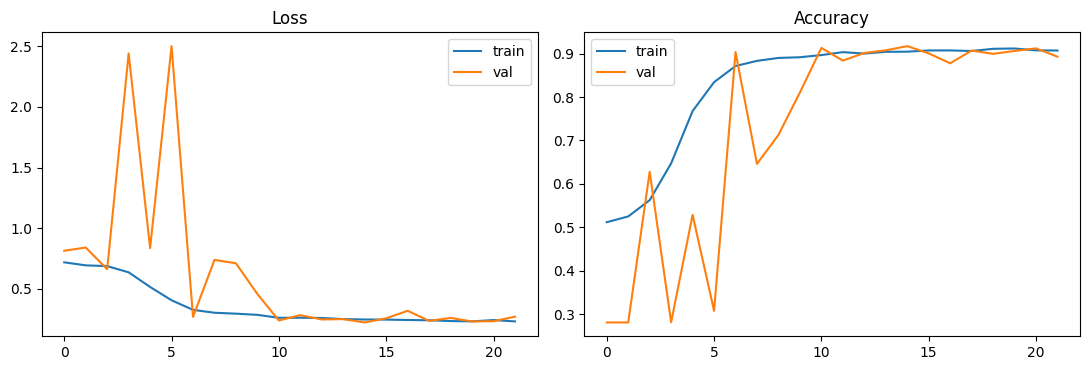

In [7]:
# ==============================================================================
# 7. Visualización de curvas de pérdida y precisión (Train vs Validación)
# ==============================================================================
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/A_curvas.png", dpi=130); plt.show()


## 5. Evaluación
Elegimos el **umbral** que maximiza F1 en *validación* (con class weights, 0.5 no siempre es lo mejor) y lo reportamos sobre *test*. Ese umbral se guarda para usarlo en la app.

Mejor umbral (val): 0.34 | F1 val: 0.8589

===== TEST con umbral 0.50 =====
              precision    recall  f1-score   support

   no sonríe     0.9526    0.9620    0.9573      1422
      sonríe     0.8998    0.8770    0.8883       553

    accuracy                         0.9382      1975
   macro avg     0.9262    0.9195    0.9228      1975
weighted avg     0.9379    0.9382    0.9380      1975


===== TEST con umbral 0.34 =====
              precision    recall  f1-score   support

   no sonríe     0.9626    0.9423    0.9524      1422
      sonríe     0.8593    0.9060    0.8820       553

    accuracy                         0.9322      1975
   macro avg     0.9110    0.9242    0.9172      1975
weighted avg     0.9337    0.9322    0.9327      1975



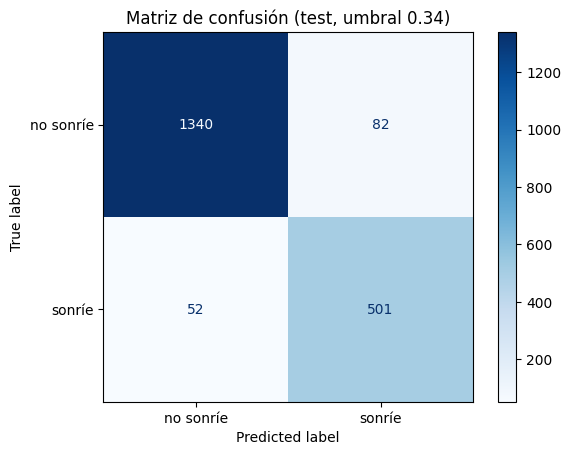

AUC test: 0.9731


In [8]:
# ==============================================================================
# 8. Selección del umbral óptimo de decisión mediante F1-Score en Validación
# ==============================================================================
# El umbral estándar de 0.50 suele ser subóptimo en problemas con clases desbalanceadas.
# Metodología rigurosa:
#   1. Se evalúa una rejilla de umbrales t en [0.10, 0.90] con paso 0.01.
#   2. Se calcula el F1-Score de la clase 'sonríe' EXCLUSIVAMENTE sobre el conjunto de
#      validación (X_val, y_val), para evitar el sesgo de optimizar sobre el test set.
#   3. np.argmax(f1s) identifica el umbral que maximiza el compromiso armónico entre
#      precisión (evitar falsas alarmas) y exhaustividad (detectar todas las sonrisas).
#   4. El umbral seleccionado se evalúa finalmente sobre el conjunto de test independiente.
p_val  = model.predict(X_val,  verbose=0).ravel()
p_test = model.predict(X_test, verbose=0).ravel()

thresholds = np.arange(0.10, 0.91, 0.01)
f1s = [f1_score(y_val, p_val >= t) for t in thresholds]
best_thr = float(thresholds[int(np.argmax(f1s))])
print(f"Mejor umbral (val): {best_thr:.2f} | F1 val: {max(f1s):.4f}")

# Comparación: Umbral por defecto 0.50 vs Umbral Óptimo por F1 en Test
for thr in (0.5, best_thr):
    pred = (p_test >= thr).astype(int)
    print(f"\n===== TEST con umbral {thr:.2f} =====")
    print(classification_report(y_test, pred, target_names=["no sonríe", "sonríe"], digits=4))

pred_best = (p_test >= best_thr).astype(int)
cm = confusion_matrix(y_test, pred_best)
ConfusionMatrixDisplay(cm, display_labels=["no sonríe", "sonríe"]).plot(cmap="Blues")
plt.title(f"Matriz de confusión (test, umbral {best_thr:.2f})")
plt.savefig(f"{OUT}/A_confusion.png", dpi=130); plt.show()

auc = roc_auc_score(y_test, p_test)
print("AUC test:", round(auc, 4))


## 6. Velocidad de inferencia (referencia; en la laptop se medirá de nuevo)

In [9]:
# ==============================================================================
# 9. Medición de latencia de inferencia por rostro
# ==============================================================================
# Calentamiento inicial de 20 pasadas (warm-up) para compilar trazas internas,
# seguido de 200 pasadas para estimar el tiempo promedio en milisegundos por rostro.
sample = X_test[:1]
for _ in range(20): model(sample, training=False)          # calentamiento
t0 = time.time()
for _ in range(200): model(sample, training=False)
ms = (time.time() - t0) / 200 * 1000
print(f"~{ms:.2f} ms por cara en este entorno")


~25.25 ms por cara en este entorno


## 7. Guardado (descarga todo desde la pestaña *Output* al terminar)

In [10]:
# ==============================================================================
# 10. Almacenamiento del modelo entrenado y exportación de métricas JSON
# ==============================================================================
# El archivo A_metrics.json almacena el umbral óptimo ('umbral_recomendado')
# que es leído directamente por la aplicación en tiempo real al cargar el modelo.
model.save(f"{OUT}/model_A_cnn.keras")

metrics = {
    "modelo": "A_cnn_desde_cero",
    "quick_test": QUICK_TEST,
    "epocas_ejecutadas": len(history.history["loss"]),
    "minutos_entrenamiento": round(train_minutes, 2),
    "umbral_recomendado": best_thr,
    "test_accuracy": float((pred_best == y_test).mean()),
    "test_f1_sonrie": float(f1_score(y_test, pred_best)),
    "test_auc": float(auc),
    "matriz_confusion": cm.tolist(),
    "ms_por_cara": round(ms, 2),
    "preprocesado": "gris, 64x64, float32 0-255, forma (1,64,64,1); Rescaling(1/255) dentro del modelo",
}
with open(f"{OUT}/A_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(json.dumps(metrics, indent=2, ensure_ascii=False))
print("\nArchivos en /kaggle/working:", os.listdir(OUT))


{
  "modelo": "A_cnn_desde_cero",
  "quick_test": false,
  "epocas_ejecutadas": 22,
  "minutos_entrenamiento": 3.0,
  "umbral_recomendado": 0.33999999999999986,
  "test_accuracy": 0.9321518987341773,
  "test_f1_sonrie": 0.8820422535211268,
  "test_auc": 0.973063433566558,
  "matriz_confusion": [
    [
      1340,
      82
    ],
    [
      52,
      501
    ]
  ],
  "ms_por_cara": 25.25,
  "preprocesado": "gris, 64x64, float32 0-255, forma (1,64,64,1); Rescaling(1/255) dentro del modelo"
}

Archivos en /kaggle/working: ['A_metrics.json', 'A_curvas.png', '__notebook__.ipynb', 'A_confusion.png', 'model_A_cnn.keras']
